## K-Nearest Neighbors (KNN)

- `K` - number of neighbours to average (`K = 3`)
- `X` - features, 2D array
- `y` - target, 1D array

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [57]:
df = pd.read_csv('Housing.csv')
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [59]:
df['mainroad'] = df['mainroad'].map({'yes': 1, 'no':0})
df['guestroom'] = df['guestroom'].map({'yes': 1, 'no':0})
df['basement'] = df['basement'].map({'yes': 1, 'no':0})
df['hotwaterheating'] = df['hotwaterheating'].map({'yes': 1, 'no':0})
df['airconditioning'] = df['airconditioning'].map({'yes': 1, 'no':0})
df['prefarea'] = df['prefarea'].map({'yes': 1, 'no':0})
df['furnishingstatus'] = df['furnishingstatus'].map({'furnished':1,'unfurnished':0,'semi-furnished': 1})


In [60]:
df.head(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1
5,10850000,7500,3,3,1,1,0,1,0,1,2,1,1
6,10150000,8580,4,3,4,1,0,0,0,1,2,1,1
7,10150000,16200,5,3,2,1,0,0,0,0,0,0,0
8,9870000,8100,4,1,2,1,1,1,0,1,2,1,1
9,9800000,5750,3,2,4,1,1,0,0,1,1,1,0


In [61]:
y = df['price'] /1_000_000
y

0      13.30000
1      12.25000
2      12.25000
3      12.21500
4      11.41000
         ...   
540     1.82000
541     1.76715
542     1.75000
543     1.75000
544     1.75000
Name: price, Length: 545, dtype: float64

In [62]:
X= df.iloc[:,1:]
X

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,7420,4,2,3,1,0,0,0,1,2,1,1
1,8960,4,4,4,1,0,0,0,1,3,0,1
2,9960,3,2,2,1,0,1,0,0,2,1,1
3,7500,4,2,2,1,0,1,0,1,3,1,1
4,7420,4,1,2,1,1,1,0,1,2,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
540,3000,2,1,1,1,0,1,0,0,2,0,0
541,2400,3,1,1,0,0,0,0,0,0,0,1
542,3620,2,1,1,1,0,0,0,0,0,0,0
543,2910,3,1,1,0,0,0,0,0,0,0,1


In [63]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [64]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error,r2_score,root_mean_squared_error

pipe = Pipeline([
    ('scale', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=3))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)


In [65]:
print('With Scaling:')
print('MAE:', mean_absolute_error(y_test,y_pred))
print('RMAE:', root_mean_squared_error(y_test,y_pred))
print('R2 Score:', r2_score(y_test,y_pred))


With Scaling:
MAE: 1.0477968195718654
RMAE: 1.4615682270571972
R2 Score: 0.5773762005025882


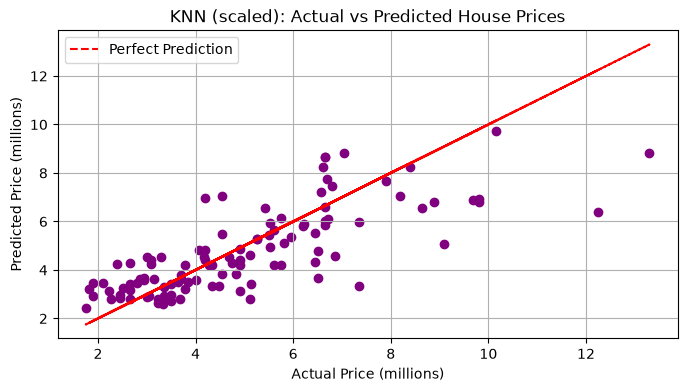

In [66]:
plt.figure(figsize=(8,4))
plt.scatter(y_test,y_pred, color='purple')
plt.plot(y_test,y_test,color = 'red', linestyle='--', label='Perfect Prediction')

plt.title('KNN (scaled): Actual vs Predicted House Prices')
plt.xlabel('Actual Price (millions)')
plt.ylabel('Predicted Price (millions)')
plt.legend()
plt.grid(True)

In [70]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'model__n_neighbors': range(1,21),
    'model__weights': ['uniform','distance']
}

grid_search= GridSearchCV(pipe,param_grid,cv=5,scoring='r2')
grid_search.fit(X_train,y_train)

print('Best params:', grid_search.best_params_)
print('Best cross-validated R2:', grid_search.best_score_)

Best params: {'model__n_neighbors': 11, 'model__weights': 'distance'}
Best cross-validated R2: 0.6315922369503717


In [72]:
best_pred = grid_search.best_estimator_.predict(X_test)

print('Tuned model on the test set')
print(' MAE:', mean_absolute_error(y_test,best_pred))
print('RMAE:', root_mean_squared_error(y_test,best_pred))
print(' R2 Score:', r2_score(y_test,best_pred))

Tuned model on the test set
 MAE: 1.0238604554009376
RMAE: 1.4444145986554089
 R2 Score: 0.5872381961035305


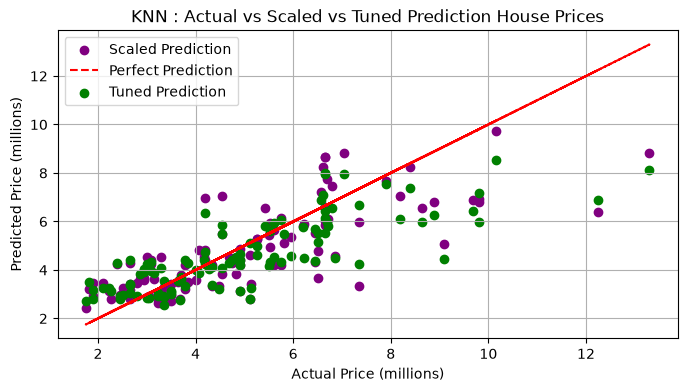

In [77]:
plt.figure(figsize=(8,4))
plt.scatter(y_test,y_pred, color='purple',label ='Scaled Prediction')
plt.plot(y_test,y_test,color = 'red', linestyle='--', label='Perfect Prediction')
plt.scatter(y_test,best_pred, color='green', label='Tuned Prediction')

plt.title('KNN : Actual vs Scaled vs Tuned Prediction House Prices')
plt.xlabel('Actual Price (millions)')
plt.ylabel('Predicted Price (millions)')
plt.legend()
plt.grid(True)